<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# A Swedish winter: snow on land, ice on the sea ❄️
### Copernicus Climate Change Service · ERA5-Land and ERA5 · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/sweden/winter_era5.ipynb)

The winter of 2025–26 brought snow to almost all of Sweden and ice to a large part of the Baltic. The ice
grew from the Bothnian Bay southwards and reached its largest extent on **Friday 20 February 2026**, when snow also covered
almost the whole country. This notebook maps that day from two Copernicus reanalyses that ECMWF produces for the European
Union: **snow depth** on land from ERA5-Land (about 9 km) and **sea-ice cover** from ERA5 (about 31 km).

Before you run it, also accept the licence of the [ERA5 dataset](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download):
this notebook uses both.

**What you need:** a Google account (to use Colab) and a free Copernicus account (next step). No fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ERA5-Land](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land), about 9 km | snow depth, 20 February 2026, 06 UTC | Copernicus licence, free |
| [ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels), about 31 km | sea-ice cover, 20 February 2026, 12 UTC | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to Sweden (SMHI, Norrköping), 2026. ERA5 is coarse for an archipelago coast: expect differences from the SMHI and FMI ice charts.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import cartopy.crs as ccrs, cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

## 1 · Choose the day and the area

In [4]:
DAY  = "2026-02-20"
AREA = [70.5, 4.0, 54.0, 32.0]               # north, west, south, east: Sweden, the Baltic and its gulfs
PLACES = [("Stockholm", 59.329, 18.069), ("Norrköping", 58.588, 16.192), ("Gothenburg", 57.709, 11.975),
          ("Malmö", 55.605, 13.004), ("Luleå", 65.584, 22.155)]

## 2 · Get snow depth (ERA5-Land) and sea ice (ERA5)

In [5]:
when = {"year": DAY[:4], "month": DAY[5:7], "day": DAY[8:], "area": AREA, "data_format": "grib"}
snow = ekd.from_source("cds", "reanalysis-era5-land", {"variable": "snow_depth", "time": "06:00", **when}).to_xarray()
ice = ekd.from_source("cds", "reanalysis-era5-single-levels", {"product_type": "reanalysis",
                      "variable": "sea_ice_cover", "time": "12:00", **when}).to_xarray()
sde = snow[list(snow.data_vars)[0]].squeeze() * 100           # metres -> cm
ci = ice[list(ice.data_vars)[0]].squeeze() * 100              # fraction -> %

# ice extent: the area of 0.25° cells at least 15% covered (the usual threshold), Baltic box only
baltic = ci.sortby("latitude").sel(latitude=slice(53.5, 66.5), longitude=slice(9.5, 30.5))
cell = (0.25 * 111.2) ** 2 * np.cos(np.radians(baltic.latitude))   # km² per cell
extent = float((cell * (baltic >= 15)).sum())
print(f"{DAY}: ice on about {extent:,.0f} km² of the Baltic and the big lakes (ERA5)")
for n, la, lo in PLACES:
    print(f"  snow at {n:10s} {float(sde.sel(latitude=la, longitude=lo, method='nearest')):5.0f} cm")

2026-02-20: ice on about 191,606 km² of the Baltic and the big lakes (ERA5)
  snow at Stockholm      9 cm
  snow at Norrköping    11 cm
  snow at Gothenburg    10 cm
  snow at Malmö        nan cm
  snow at Luleå         26 cm


## 3 · Map it

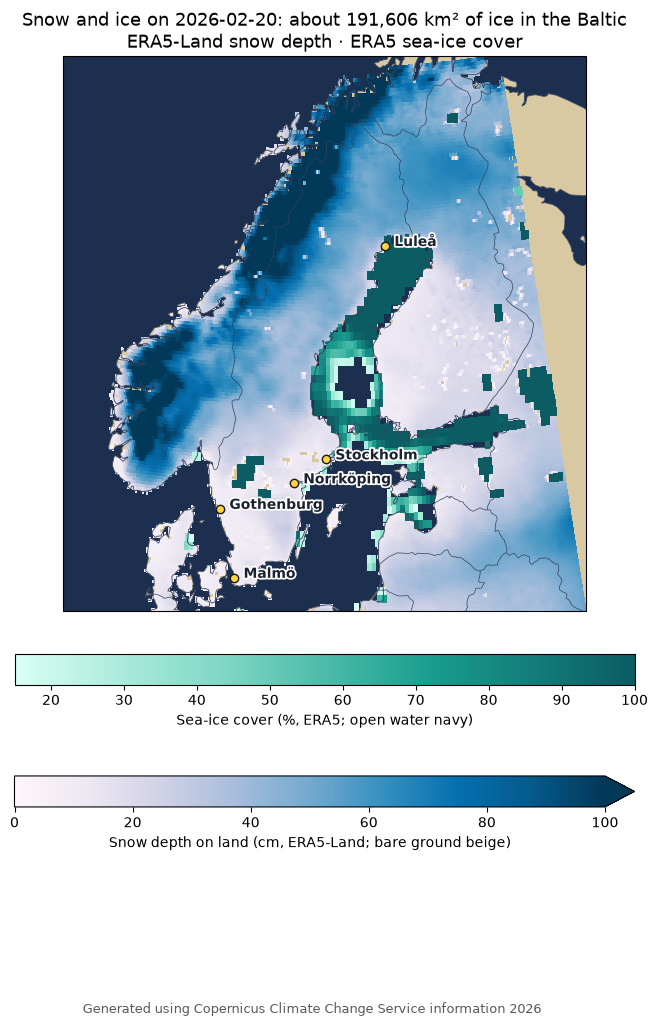

In [6]:
snow_cmap = plt.get_cmap("PuBu")
ice_cmap = LinearSegmentedColormap.from_list("ice", ["#d9fff4", "#7fd8c4", "#1a9e8f", "#0b5d63"])
fig = plt.figure(figsize=(10, 11))
ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=18, central_latitude=62))
ax.set_extent([AREA[1], AREA[3], AREA[2], AREA[0]], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.OCEAN, facecolor="#1d2f4e"); ax.add_feature(cfeature.LAND, facecolor="#d8c9a3")
s = ax.pcolormesh(sde.longitude, sde.latitude, sde.where(sde >= 1), cmap=snow_cmap, vmin=0, vmax=100,
                  shading="auto", transform=ccrs.PlateCarree())
i = ax.pcolormesh(ci.longitude, ci.latitude, ci.where(ci >= 15), cmap=ice_cmap, vmin=15, vmax=100,
                  shading="auto", transform=ccrs.PlateCarree())
ax.coastlines("50m", linewidth=0.6, color="#33415c"); ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="#33415c")
for n, la, lo in PLACES:
    ax.plot(lo, la, "o", ms=6, mfc="#ffd23f", mec="#1a1a1a", transform=ccrs.PlateCarree(), zorder=10)
    ax.text(lo, la, f"  {n}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
            color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
plt.colorbar(s, ax=ax, orientation="horizontal", pad=0.02, shrink=0.8, extend="max",
             label="Snow depth on land (cm, ERA5-Land; bare ground beige)")
plt.colorbar(i, ax=ax, orientation="horizontal", pad=0.06, shrink=0.8,
             label="Sea-ice cover (%, ERA5; open water navy)")
ax.set_title(f"Snow and ice on {DAY}: about {extent:,.0f} km² of ice in the Baltic\nERA5-Land snow depth · ERA5 sea-ice cover",
             fontsize=13)
fig.text(0.5, 0.01, "Generated using Copernicus Climate Change Service information 2026", ha="center", fontsize=9, color="0.35")
plt.savefig("winter_era5.png", dpi=110, bbox_inches="tight")
plt.show()

## 4 · Your turn 🌍

- **Early and late winter:** `DAY = "2026-01-05"` (the ice just starting in the Bothnian Bay) or `"2026-04-20"` (the melt).
- **Another winter:** change the year, for example `"2011-02-20"` or `"1987-02-20"`; both datasets go back decades.
- **Snow cover instead of depth:** ask ERA5-Land for `"snow_cover"` (%) as well.
- **Your own area:** change `AREA` and the Baltic box in step 2, for example to the Gulf of Finland only.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)